In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("imported succesfully")

imported succesfully


In [3]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("File read successfully")


File read successfully


In [4]:
df['Description'] = df['Description'].fillna('Unknown')

In [5]:
df = df.drop_duplicates()

In [6]:
print("Negative quantities:",
      (df['Quantity'] < 0).sum())

print("Zero prices:",
      (df['UnitPrice'] == 0).sum())

print("Negative prices:",
      (df['UnitPrice'] < 0).sum())

Negative quantities: 10587
Zero prices: 2510
Negative prices: 2


In [7]:
df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')

In [8]:
df['IsCancelled'].value_counts()

IsCancelled
False    527390
True       9251
Name: count, dtype: int64

In [9]:
cancelled_data = df[df['IsCancelled'] == True]

cancelled_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,True
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,True
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True


In [10]:
df['IsNegativeQuantity'] = df['Quantity'] < 0

In [11]:
df['IsReturnLike'] = (
    (df['Quantity'] < 0) &
    (df['IsCancelled'] == False)
)

In [12]:
return_data = df[df['IsReturnLike'] == True]

return_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsNegativeQuantity,IsReturnLike
2406,536589,21777,Unknown,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,False,True,True
4347,536764,84952C,Unknown,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,False,True,True
7188,536996,22712,Unknown,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False,True,True
7189,536997,22028,Unknown,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False,True,True
7190,536998,85067,Unknown,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,False,True,True


In [13]:
print("Cancellation rows:",
      df['IsCancelled'].sum())

print("Return-like rows:",
      df['IsReturnLike'].sum())

Cancellation rows: 9251
Return-like rows: 1336


In [14]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Year'] = df['InvoiceDate'].dt.year

df['Month'] = df['InvoiceDate'].dt.month

df['Day'] = df['InvoiceDate'].dt.day

df['Hour'] = df['InvoiceDate'].dt.hour

df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

In [15]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
print(df.head())

Dataset shape: (536641, 16)

Missing values:
InvoiceNo                  0
StockCode                  0
Description                0
Quantity                   0
InvoiceDate                0
UnitPrice                  0
CustomerID            135037
Country                    0
IsCancelled                0
IsNegativeQuantity         0
IsReturnLike               0
Year                       0
Month                      0
Day                        0
Hour                       0
DayOfWeek                  0
dtype: int64

Duplicate records:
0

Data types:
InvoiceNo                     object
StockCode                     object
Description                   object
Quantity                       int64
InvoiceDate           datetime64[ns]
UnitPrice                    float64
CustomerID                   float64
Country                       object
IsCancelled                     bool
IsNegativeQuantity              bool
IsReturnLike                    bool
Year                           int32

In [16]:
df.to_csv("cleaned_online_retail.csv", index=False)

In [17]:
print("Total records:", len(df))

print("\nCancelled records:")
print(df["IsCancelled"].value_counts())

print("\nNegative quantity records:")
print(df["IsNegativeQuantity"].value_counts())

print("\nReturn-like records:")
print(df["IsReturnLike"].value_counts())

print("\nCancellation vs Negative Quantity:")
print(pd.crosstab(
    df["IsCancelled"],
    df["IsNegativeQuantity"]
))

Total records: 536641

Cancelled records:
IsCancelled
False    527390
True       9251
Name: count, dtype: int64

Negative quantity records:
IsNegativeQuantity
False    526054
True      10587
Name: count, dtype: int64

Return-like records:
IsReturnLike
False    535305
True       1336
Name: count, dtype: int64

Cancellation vs Negative Quantity:
IsNegativeQuantity   False  True 
IsCancelled                      
False               526054   1336
True                     0   9251


In [18]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

df[[
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "TotalAmount"
]].head()

,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [19]:
cancelled = df[df["IsCancelled"] == True]

country_cancel = (
    cancelled.groupby("Country")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print(country_cancel)

Country
United Kingdom    7821
Germany            453
EIRE               301
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
dtype: int64


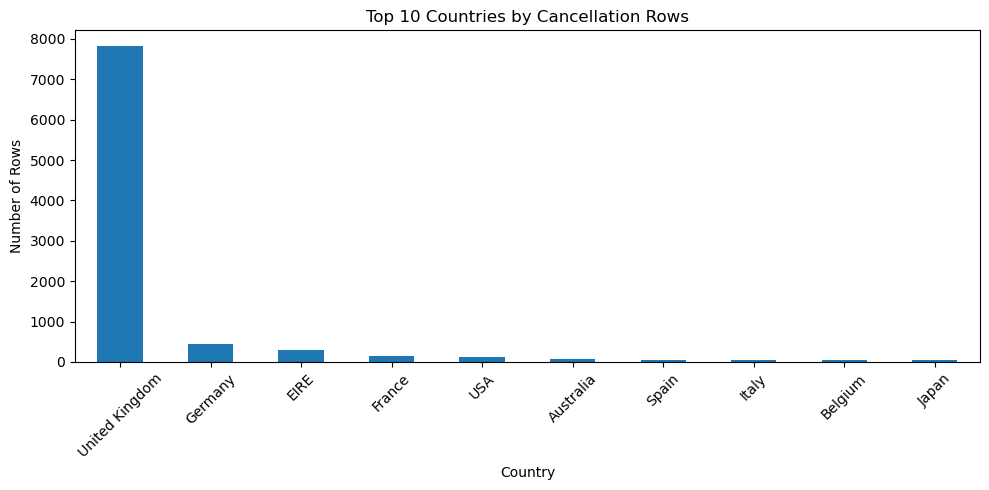

In [20]:
import matplotlib.pyplot as plt

country_cancel.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Countries by Cancellation Rows")
plt.xlabel("Country")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

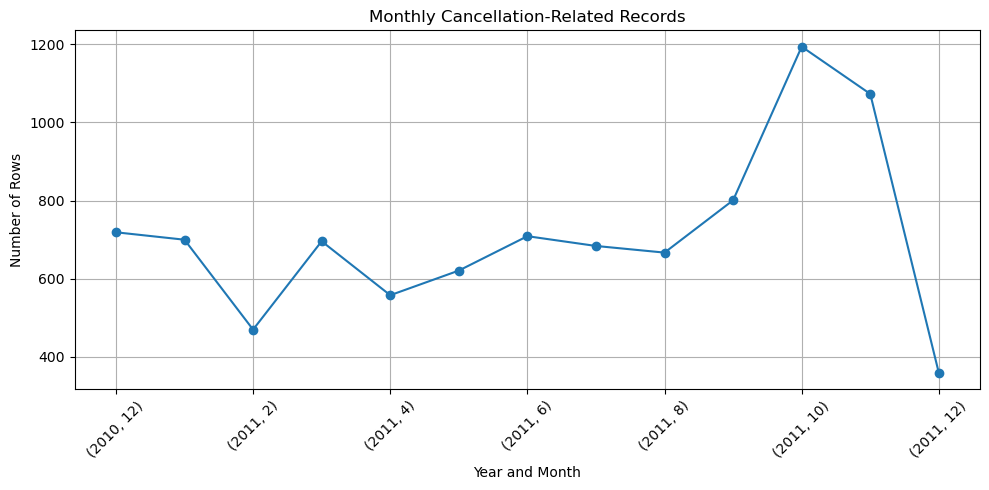

In [21]:
monthly_cancel = (
    cancelled.groupby(["Year", "Month"])
    .size()
)

monthly_cancel.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Cancellation-Related Records")
plt.xlabel("Year and Month")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
top_products = (
    cancelled.groupby("Description")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
Manual                               244
REGENCY CAKESTAND 3 TIER             180
POSTAGE                              126
JAM MAKING SET WITH JARS              87
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      73
SAMPLES                               60
STRAWBERRY CERAMIC TRINKET BOX        54
ROSES REGENCY TEACUP AND SAUCER       54
RECIPE BOX PANTRY YELLOW DESIGN       47
dtype: int64


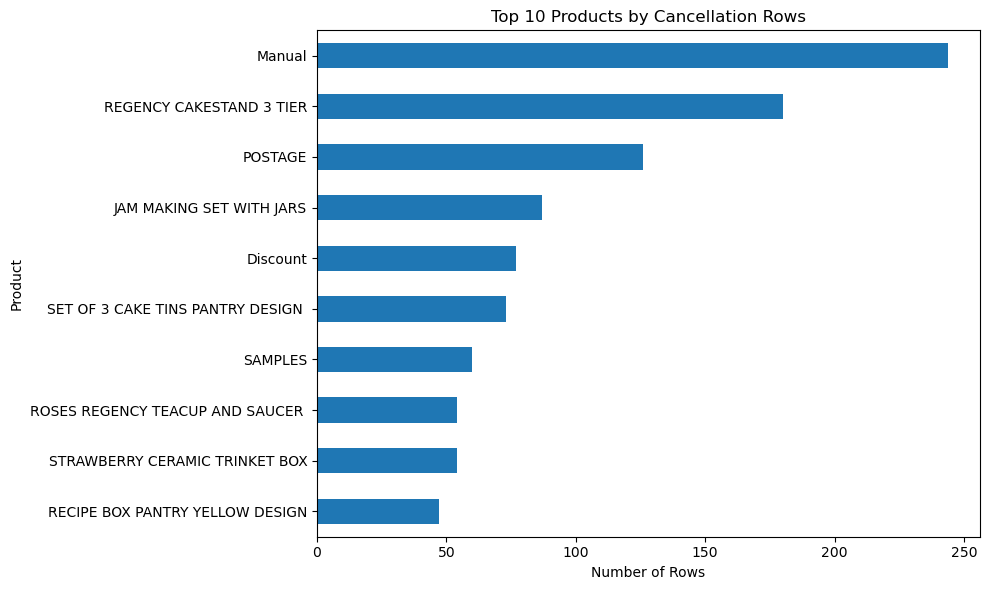

In [23]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Cancellation Rows")
plt.xlabel("Number of Rows")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [24]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

customer_features = customer_df.groupby("CustomerID").agg(
    TotalTransactions=("InvoiceNo", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    TotalAmount=("TotalAmount", "sum"),
    CancellationRows=("IsCancelled", "sum"),
    NegativeQuantityRows=("IsNegativeQuantity", "sum")
).reset_index()

customer_features.head()

,CustomerID,TotalTransactions,TotalQuantity,TotalAmount,CancellationRows,NegativeQuantityRows
0,12346.0,2,0,0.00,1,1
1,12347.0,7,2458,4310.00,0,0
2,12348.0,4,2341,1797.24,0,0
3,12349.0,1,631,1757.55,0,0
4,12350.0,1,197,334.40,0,0


In [25]:
customer_row_counts = (
    customer_df.groupby("CustomerID")
    .size()
)

customer_features["CancellationRate"] = (
    customer_features["CancellationRows"].to_numpy()
    / customer_row_counts.to_numpy()
)

In [26]:
product_features = df.groupby("StockCode").agg(
    TotalTransactions=("InvoiceNo", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    TotalAmount=("TotalAmount", "sum"),
    CancellationRows=("IsCancelled", "sum"),
    NegativeQuantityRows=("IsNegativeQuantity", "sum")
).reset_index()

product_features.head()

,StockCode,TotalTransactions,TotalQuantity,TotalAmount,CancellationRows,NegativeQuantityRows
0,10002,73,1037,759.89,0,1
1,10080,24,495,119.09,0,0
2,10120,29,192,40.32,0,0
3,10125,91,1295,993.99,0,0
4,10133,198,2764,1535.40,1,2


In [27]:
df.to_csv("retail_eda.csv", index=False)

customer_features.to_csv(
    "customer_features.csv",
    index=False
)

product_features.to_csv(
    "product_features.csv",
    index=False
)

print("All files saved successfully!")

All files saved successfully!


In [29]:
df = pd.read_csv("retail_eda.csv")
customer_features = pd.read_csv("customer_features.csv")
product_features = pd.read_csv("product_features.csv")

print("\nAll three CSV files loaded successfully!")


All three CSV files loaded successfully!


In [30]:
print("\nTransaction dataset:", df.shape)
print("Customer dataset:", customer_features.shape)
print("Product dataset:", product_features.shape)


Transaction dataset: (536641, 17)
Customer dataset: (4372, 7)
Product dataset: (4070, 6)


In [31]:
print("\nFirst five customer records:")
display(customer_features.head())


First five customer records:


,CustomerID,TotalTransactions,TotalQuantity,TotalAmount,CancellationRows,NegativeQuantityRows,CancellationRate
0,12346.0,2,0,0.00,1,1,0.5
1,12347.0,7,2458,4310.00,0,0,0.0
2,12348.0,4,2341,1797.24,0,0,0.0
3,12349.0,1,631,1757.55,0,0,0.0
4,12350.0,1,197,334.40,0,0,0.0


In [32]:
print("Starting customer cancellation analysis...")

# Select the top 10 customers by cancellation rows
top_customers = customer_features.nlargest(
    10, "CancellationRows"
)

print("\nTop 10 customers identified successfully!")

Starting customer cancellation analysis...

Top 10 customers identified successfully!


In [33]:
display(top_customers)

,CustomerID,TotalTransactions,TotalQuantity,TotalAmount,CancellationRows,NegativeQuantityRows,CancellationRate
1895,14911.0,248,77155,1.324587e+05,226,226,0.038318
4042,17841.0,169,22628,3.986905e+04,136,136,0.017409
3801,17511.0,46,63012,8.812538e+04,113,113,0.105019
2192,15311.0,118,37673,5.928419e+04,112,112,0.045198
213,12607.0,2,0,3.552714e-15,101,101,0.500000
1523,14410.0,15,290,5.734500e+02,92,92,0.326241
1078,13798.0,63,23515,3.635287e+04,89,89,0.203196
1674,14606.0,128,5941,1.163335e+04,82,82,0.029721
587,13113.0,40,2594,1.051000e+04,79,79,0.282143
100,12471.0,49,7953,1.870552e+04,71,71,0.133962


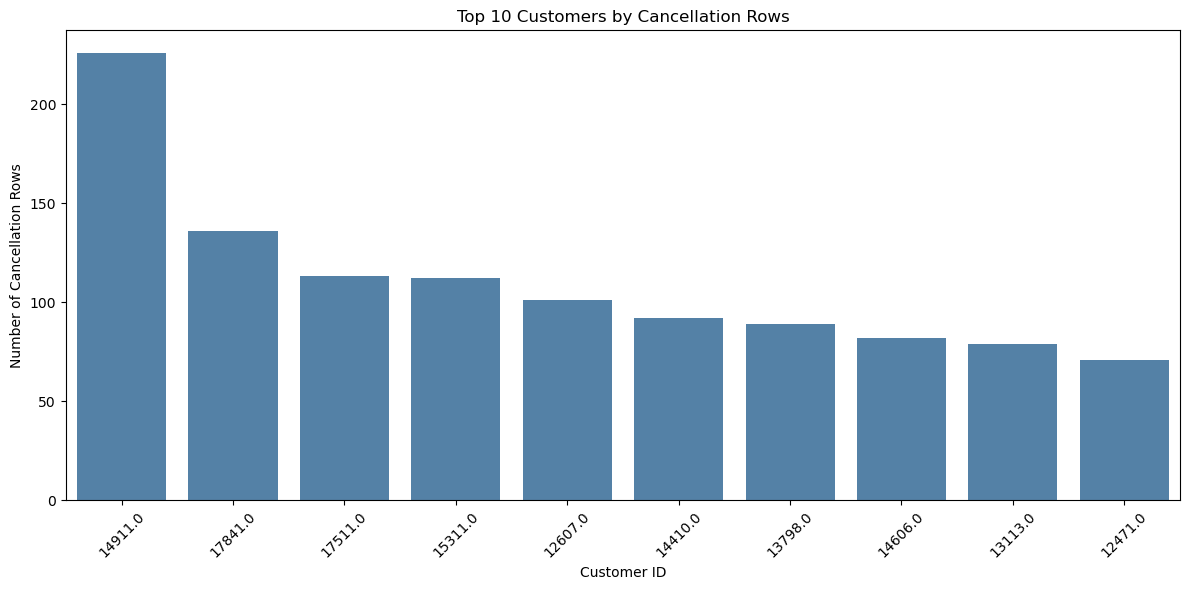


Customer cancellation graph generated successfully!


In [34]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x="CustomerID",
    y="CancellationRows",
    color="steelblue",
    order=top_customers["CustomerID"]
)

plt.title("Top 10 Customers by Cancellation Rows")
plt.xlabel("Customer ID")
plt.ylabel("Number of Cancellation Rows")
plt.xticks(rotation=45)
plt.tight_layout()

# Display graph
plt.show()

print("\nCustomer cancellation graph generated successfully!")

Starting product cancellation analysis...

Top 10 products identified successfully!


,StockCode,TotalTransactions,TotalQuantity,TotalAmount,CancellationRows,NegativeQuantityRows
4060,M,517,2924,-69034.19,244,244
1271,22423,2172,12954,164459.49,180,183
4062,POST,1254,6353,66230.64,126,126
1785,22960,1220,8459,36069.34,87,87
4042,D,65,-1194,-5696.22,77,77
1554,22720,1462,7279,37378.79,73,75
391,21232,888,11459,15806.80,60,60
4063,S,19,-58,-3039.65,60,60
1533,22699,1120,9428,27906.57,54,54
1070,22197,1442,56427,50967.92,50,50


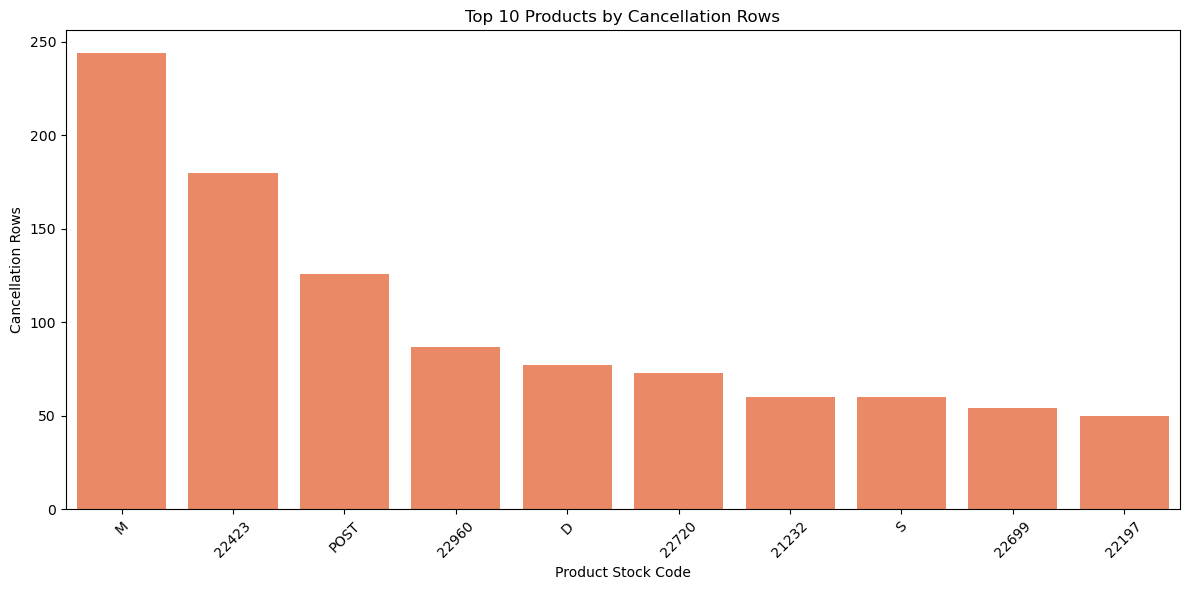


Product cancellation graph generated successfully!


In [35]:
print("Starting product cancellation analysis...")

# Select products with highest cancellation rows
top_products = product_features.nlargest(
    10, "CancellationRows"
)

print("\nTop 10 products identified successfully!")

# Display product information
display(top_products)

# Create bar graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="StockCode",
    y="CancellationRows",
    color="coral",
    order=top_products["StockCode"]
)

plt.title("Top 10 Products by Cancellation Rows")
plt.xlabel("Product Stock Code")
plt.ylabel("Cancellation Rows")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

print("\nProduct cancellation graph generated successfully!")

In [36]:
plt.savefig(
    "product_cancellation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

print("Graph saved successfully!")

Graph saved successfully!


<Figure size 640x480 with 0 Axes>

In [37]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [38]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 536641
Total columns: 17


In [39]:
print("\nAvailable columns:")
print(df.columns.tolist())


Available columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancelled', 'IsNegativeQuantity', 'IsReturnLike', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'TotalAmount']


In [40]:

print("Starting transaction validation...")

# Recreate labels from original transaction fields
df["IsCancelled"] = (
    df["InvoiceNo"].astype(str).str.startswith("C")
)

df["IsNegativeQuantity"] = df["Quantity"] < 0

# Return-like is a proxy, not a confirmed return
df["IsReturnLike"] = df["IsNegativeQuantity"]

# Calculate transaction amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

# Positive purchase amount
df["PurchaseAmount"] = np.where(
    (df["Quantity"] > 0) & (df["UnitPrice"] > 0),
    df["TotalAmount"],
    0
)

# Absolute value of negative-quantity credit records
df["CreditAmount"] = np.where(
    df["Quantity"] < 0,
    abs(df["TotalAmount"]),
    0
)

Starting transaction validation...


In [41]:
print("\nZero or negative prices:",
      (df["UnitPrice"] <= 0).sum())

print("Negative quantity records:",
      df["IsNegativeQuantity"].sum())

print("Cancellation rows:",
      df["IsCancelled"].sum())

print("\nTransaction features created successfully!")

display(df.head())


Zero or negative prices: 2512
Negative quantity records: 10587
Cancellation rows: 9251

Transaction features created successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,IsNegativeQuantity,IsReturnLike,Year,Month,Day,Hour,DayOfWeek,TotalAmount,PurchaseAmount,CreditAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,False,False,2010,12,1,8,Wednesday,15.30,15.30,0.0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,1,8,Wednesday,20.34,20.34,0.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,False,False,2010,12,1,8,Wednesday,22.00,22.00,0.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,1,8,Wednesday,20.34,20.34,0.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,False,False,2010,12,1,8,Wednesday,20.34,20.34,0.0


In [42]:

print("Starting customer feature engineering...")

# Remove missing CustomerID only for customer analysis
customer_df = df.dropna(subset=["CustomerID"]).copy()

# Create invoice-level records
customer_invoices = customer_df.groupby(
    ["CustomerID", "InvoiceNo"],
    as_index=False
).agg(
    IsCancelled=("IsCancelled", "max"),
    PurchaseAmount=("PurchaseAmount", "sum"),
    CreditAmount=("CreditAmount", "sum")
)

# Aggregate invoices for each customer
customer_features = customer_invoices.groupby(
    "CustomerID"
).agg(
    TotalInvoices=("InvoiceNo", "nunique"),
    CancellationInvoices=("IsCancelled", "sum"),
    TotalPurchaseAmount=("PurchaseAmount", "sum"),
    TotalCreditAmount=("CreditAmount", "sum")
).reset_index()

# Derive purchase invoice count
customer_features["PurchaseInvoices"] = (
    customer_features["TotalInvoices"]
    - customer_features["CancellationInvoices"]
)

# Calculate cancellation invoice rate
customer_features["CancellationRate"] = (
    customer_features["CancellationInvoices"]
    / customer_features["TotalInvoices"]
)

# Average purchase invoice value
customer_features["AvgPurchaseValue"] = (
    customer_features["TotalPurchaseAmount"]
    / customer_features["PurchaseInvoices"].replace(0, np.nan)
)

# Fill undefined averages with zero
customer_features["AvgPurchaseValue"] = (
    customer_features["AvgPurchaseValue"].fillna(0)
)

print("\nCustomer features created successfully!")
print("Total customers:", len(customer_features))

display(customer_features.head())

Starting customer feature engineering...

Customer features created successfully!
Total customers: 4372


,CustomerID,TotalInvoices,CancellationInvoices,TotalPurchaseAmount,TotalCreditAmount,PurchaseInvoices,CancellationRate,AvgPurchaseValue
0,12346.0,2,1,77183.60,77183.6,1,0.5,77183.600000
1,12347.0,7,0,4310.00,0.0,7,0.0,615.714286
2,12348.0,4,0,1797.24,0.0,4,0.0,449.310000
3,12349.0,1,0,1757.55,0.0,1,0.0,1757.550000
4,12350.0,1,0,334.40,0.0,1,0.0,334.400000


Generating customer cancellation rate graph...


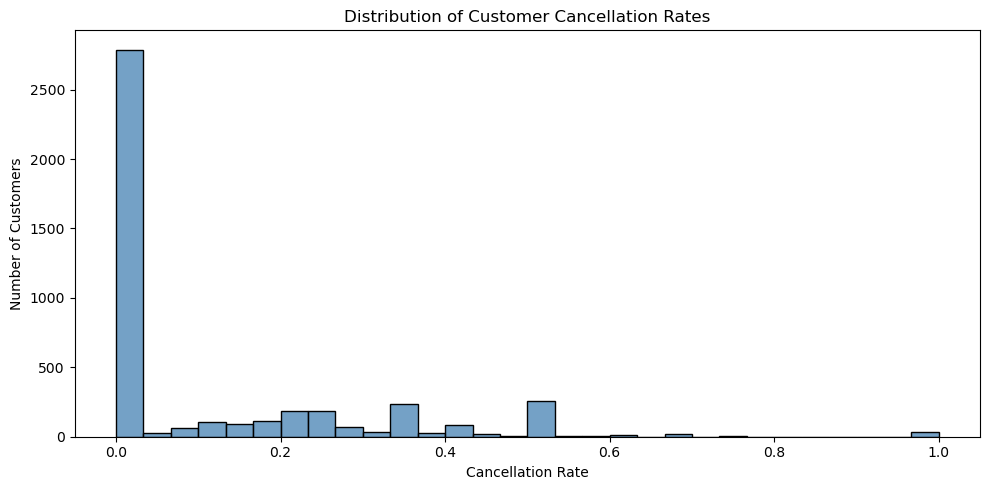

Graph generated and saved successfully!


In [43]:
print("Generating customer cancellation rate graph...")

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_features,
    x="CancellationRate",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Customer Cancellation Rates")
plt.xlabel("Cancellation Rate")
plt.ylabel("Number of Customers")

plt.tight_layout()

# Save graph before displaying
plt.savefig(
    "customer_cancellation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph generated and saved successfully!")

In [44]:
# Aggregate each product
product_features = df.groupby("StockCode").agg(
    TotalRows=("InvoiceNo", "size"),
    TotalInvoices=("InvoiceNo", "nunique"),
    CancellationRows=("IsCancelled", "sum"),
    NegativeQuantityRows=("IsNegativeQuantity", "sum"),
    TotalPurchaseAmount=("PurchaseAmount", "sum"),
    TotalCreditAmount=("CreditAmount", "sum"),
    AvgUnitPrice=("UnitPrice", "mean")
).reset_index()

# Cancellation-related row rate
product_features["CancellationRowRate"] = (
    product_features["CancellationRows"]
    / product_features["TotalRows"]
)

# Credit-to-purchase value ratio
product_features["CreditToPurchaseRatio"] = (
    product_features["TotalCreditAmount"]
    / product_features["TotalPurchaseAmount"].replace(0, np.nan)
)
print("Total products:", len(product_features))

display(product_features.head())

Total products: 4070


,StockCode,TotalRows,TotalInvoices,CancellationRows,NegativeQuantityRows,TotalPurchaseAmount,TotalCreditAmount,AvgUnitPrice,CancellationRowRate,CreditToPurchaseRatio
0,10002,73,73,0,1,759.89,0.0,1.056849,0.0,0.0
1,10080,24,24,0,0,119.09,0.0,0.376667,0.0,0.0
2,10120,29,29,0,0,40.32,0.0,0.210000,0.0,0.0
3,10123C,4,4,0,1,3.25,0.0,0.487500,0.0,0.0
4,10123G,1,1,0,1,0.00,0.0,0.000000,0.0,NaN


Generating product cancellation rate graph...


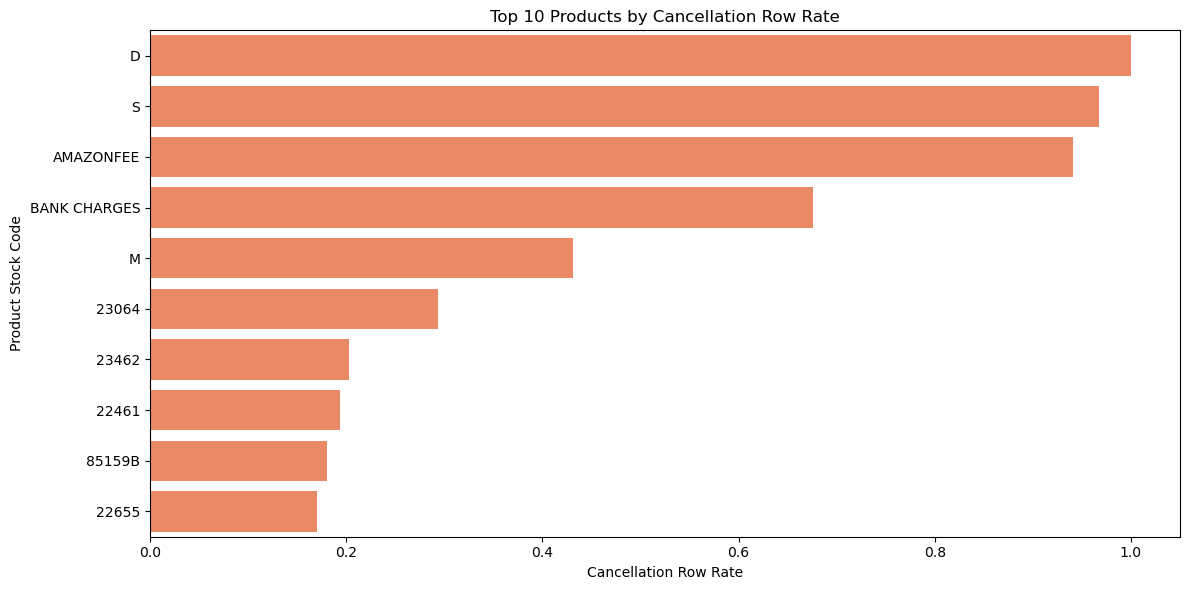

Product cancellation graph saved successfully!


In [45]:
print("Generating product cancellation rate graph...")

# Include products with at least 30 transaction rows
eligible_products = product_features[
    product_features["TotalRows"] >= 30
]

# Select the 10 highest cancellation row rates
top_products = eligible_products.nlargest(
    10, "CancellationRowRate"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="CancellationRowRate",
    y="StockCode",
    color="coral",
    order=top_products["StockCode"]
)

plt.title("Top 10 Products by Cancellation Row Rate")
plt.xlabel("Cancellation Row Rate")
plt.ylabel("Product Stock Code")

plt.tight_layout()

plt.savefig(
    "product_cancellation_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Product cancellation graph saved successfully!")

Dataset loaded successfully!
Dataset shape: (536641, 16)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Transaction features created successfully!
All required columns are available.

TEMPORAL SPLIT
Training rows: 368083
Testing rows: 168558

Past product features created.
Products in training period: 3887

PRODUCT MODEL DATA
Products available in both periods: 3023

Future risk distribution:
RiskLabel
Low       2734
Medium     211
High        78
Name: count, dtype: int64

Risk label encoding:
High = 0
Low = 1
Medium = 2

Class counts:
1    2734
2     211
0      78
Name: count, dtype: int64

Model training products: 2267
Model testing products: 756

RANDOM FOREST BASELINE MODEL

BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        19
         Low       0.91      0.99      0.95       684
      Medium       0.58      0.13      0.22        53

    accuracy                           0.91       756


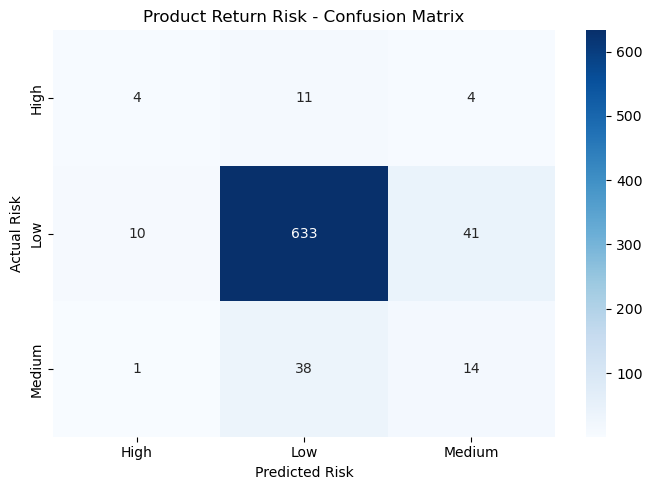


FEATURE IMPORTANCE
                 Feature  Importance
4    TotalPurchaseAmount    0.249727
3          TotalInvoices    0.224858
2           AvgUnitPrice    0.194767
0    CancellationRowRate    0.167526
1  CreditToPurchaseRatio    0.097956
5   NegativeQuantityRows    0.065167


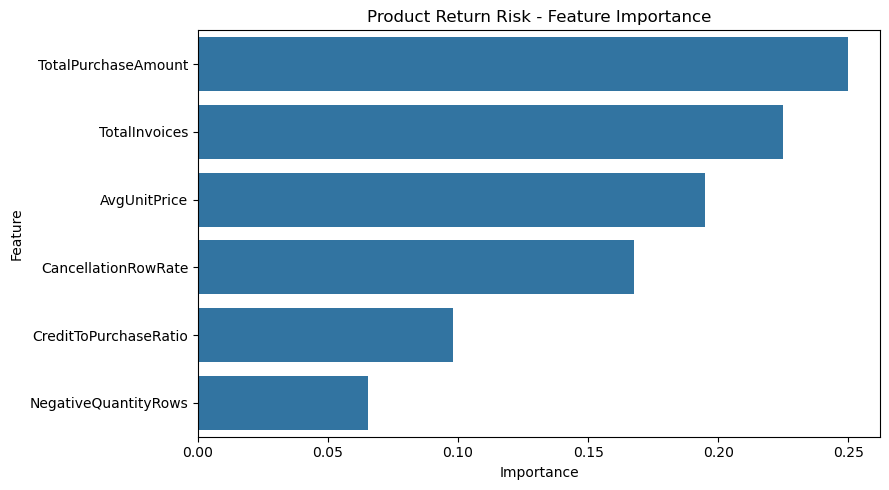


MODEL SAVED SUCCESSFULLY!
Model path: models/feature1_product_risk.pkl
Feature importance: reports/feature1_importance.csv
Confusion matrix: reports/feature1_confusion_matrix.png


In [49]:

# ============================================================
# PRODUCT RETURN RISK PREDICTION
# Random Forest Classifier
# Features = Past transaction behaviour
# Target   = Future cancellation risk
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)


# ------------------------------------------------------------
# 2. CREATE FOLDERS
# ------------------------------------------------------------

os.makedirs('models', exist_ok=True)
os.makedirs('reports', exist_ok=True)


# ------------------------------------------------------------
# 3. LOAD CLEANED DATASET
# ------------------------------------------------------------

df = pd.read_csv(
    'cleaned_online_retail.csv',
    parse_dates=['InvoiceDate']
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print(
    "Date range:",
    df['InvoiceDate'].min(),
    "to",
    df['InvoiceDate'].max()
)


# ------------------------------------------------------------
# 4. RECREATE TRANSACTION FEATURES
# ------------------------------------------------------------

# Identify cancelled invoices.
# In this dataset, cancelled invoice numbers start with C.

df['IsCancelled'] = (
    df['InvoiceNo'].astype(str).str.startswith('C')
)

# Identify negative quantity transactions.

df['IsNegativeQuantity'] = (
    df['Quantity'] < 0
)

# Return-like transactions:
# Negative quantity, but not a cancelled invoice.
# This is a proxy, not a confirmed return.

df['IsReturnLike'] = (
    (df['Quantity'] < 0) &
    (df['IsCancelled'] == False)
)

# Calculate transaction amount.

df['TotalAmount'] = (
    df['Quantity'] * df['UnitPrice']
)

# Calculate positive purchase amount.

df['PurchaseAmount'] = np.where(
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0),
    df['TotalAmount'],
    0
)

# Calculate credit amount from negative quantities.

df['CreditAmount'] = np.where(
    df['Quantity'] < 0,
    df['TotalAmount'].abs(),
    0
)

print("\nTransaction features created successfully!")


# ------------------------------------------------------------
# 5. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    'InvoiceNo',
    'InvoiceDate',
    'StockCode',
    'Quantity',
    'UnitPrice',
    'IsCancelled',
    'IsNegativeQuantity',
    'IsReturnLike',
    'TotalAmount',
    'PurchaseAmount',
    'CreditAmount'
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are available.")


# ------------------------------------------------------------
# 6. TEMPORAL TRAIN-TEST SPLIT
# ------------------------------------------------------------

# Past data is used for features.
# Future data is used to calculate the target.

CUTOFF_DATE = pd.Timestamp('2011-10-01')

df_train = df[
    df['InvoiceDate'] < CUTOFF_DATE
].copy()

df_test = df[
    df['InvoiceDate'] >= CUTOFF_DATE
].copy()

print("\nTEMPORAL SPLIT")

print("Training rows:", len(df_train))
print("Testing rows:", len(df_test))

if df_train.empty or df_test.empty:
    raise ValueError(
        "Training or testing data is empty. "
        "Check the cutoff date and InvoiceDate column."
    )


# ------------------------------------------------------------
# 7. BUILD PRODUCT-LEVEL FEATURES
# ------------------------------------------------------------

def build_product_features(data):

    """
    Creates product-level features from transaction data.
    Each row in the output represents one product.
    """

    g = data.groupby('StockCode').agg(

        # Number of unique invoices
        TotalInvoices=('InvoiceNo', 'nunique'),

        # Total transaction rows
        TotalRows=('InvoiceNo', 'size'),

        # Total positive purchase value
        TotalPurchaseAmount=('PurchaseAmount', 'sum'),

        # Average unit price
        AvgUnitPrice=('UnitPrice', 'mean'),

        # Number of negative quantity rows
        NegativeQuantityRows=(
            'IsNegativeQuantity', 'sum'
        ),

        # Number of cancellation rows
        CancelRows=('IsCancelled', 'sum'),

        # Number of return-like rows
        ReturnLikeRows=('IsReturnLike', 'sum'),

        # Total credit amount
        TotalCreditAmount=('CreditAmount', 'sum')

    ).reset_index()


    # Cancellation row rate

    g['CancellationRowRate'] = (
        g['CancelRows'] /
        g['TotalRows'].clip(lower=1)
    )


    # Credit-to-purchase ratio

    g['CreditToPurchaseRatio'] = (
        g['TotalCreditAmount'] /
        g['TotalPurchaseAmount'].replace(0, np.nan)
    )

    return g


# ------------------------------------------------------------
# 8. CREATE PAST PRODUCT FEATURES
# ------------------------------------------------------------

prod_train = build_product_features(df_train)

print("\nPast product features created.")
print("Products in training period:", len(prod_train))


# ------------------------------------------------------------
# 9. CREATE FUTURE RISK LABELS
# ------------------------------------------------------------

prod_test = build_product_features(df_test)

# Keep only product ID and future cancellation rate.

prod_test = prod_test[
    ['StockCode', 'CancellationRowRate']
].rename(
    columns={
        'CancellationRowRate': 'FutureCancellationRate'
    }
)


# Define risk categories.

def label_risk(rate):

    if rate < 0.05:
        return 'Low'

    elif rate < 0.15:
        return 'Medium'

    else:
        return 'High'


prod_test['RiskLabel'] = (
    prod_test['FutureCancellationRate'].apply(label_risk)
)


# ------------------------------------------------------------
# 10. COMBINE PAST FEATURES WITH FUTURE LABELS
# ------------------------------------------------------------

# Keep only products present in both periods.

prod_model = prod_train.merge(
    prod_test,
    on='StockCode',
    how='inner'
)

print("\nPRODUCT MODEL DATA")

print("Products available in both periods:", len(prod_model))

print("\nFuture risk distribution:")

print(
    prod_model['RiskLabel'].value_counts()
)


if len(prod_model) == 0:
    raise ValueError(
        "No common products found between training and testing periods."
    )


# ------------------------------------------------------------
# 11. SELECT FEATURES AND TARGET
# ------------------------------------------------------------

FEAT1 = [
    'CancellationRowRate',
    'CreditToPurchaseRatio',
    'AvgUnitPrice',
    'TotalInvoices',
    'TotalPurchaseAmount',
    'NegativeQuantityRows'
]

# Input features: past product behaviour.

X1 = prod_model[FEAT1].copy()

# Replace infinite and missing values.

X1 = X1.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# Output target: future risk category.

y1 = prod_model['RiskLabel']


# Convert text labels into numbers.

le1 = LabelEncoder()

y1_enc = le1.fit_transform(y1)

print("\nRisk label encoding:")

for i, label in enumerate(le1.classes_):
    print(label, "=", i)


# ------------------------------------------------------------
# 12. CHECK CLASS DISTRIBUTION
# ------------------------------------------------------------

class_counts = pd.Series(y1_enc).value_counts()

print("\nClass counts:")
print(class_counts)

number_of_classes = len(np.unique(y1_enc))

if number_of_classes < 2:
    raise ValueError(
        "Only one risk category exists. "
        "The classifier needs at least two categories."
    )

if class_counts.min() < 2:
    raise ValueError(
        "At least one risk category has fewer than 2 products. "
        "There are not enough examples for a stratified split. "
        "Review the risk thresholds or collect more data."
    )


# ------------------------------------------------------------
# 13. SPLIT PRODUCT DATA FOR MODEL EVALUATION
# ------------------------------------------------------------

# This split evaluates how well the model classifies
# products that were not included in model training.

test_size = max(
    0.25,
    number_of_classes / len(y1_enc)
)

if test_size >= 1:
    raise ValueError(
        "Not enough products for train-test evaluation."
    )

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1,
    y1_enc,
    test_size=test_size,
    random_state=42,
    stratify=y1_enc
)

print("\nModel training products:", len(X1_train))
print("Model testing products:", len(X1_test))


# ------------------------------------------------------------
# 14. TRAIN BASELINE RANDOM FOREST MODEL
# ------------------------------------------------------------

print("\n====================================")
print("RANDOM FOREST BASELINE MODEL")
print("====================================")

rf1 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf1.fit(
    X1_train,
    y1_train
)

# Predict risk categories.

y1_pred = rf1.predict(X1_test)


# Evaluate baseline model.

print("\nBASELINE CLASSIFICATION REPORT")

print(
    classification_report(
        y1_test,
        y1_pred,
        labels=np.arange(len(le1.classes_)),
        target_names=le1.classes_,
        zero_division=0
    )
)

print(
    "Baseline Macro F1:",
    f1_score(
        y1_test,
        y1_pred,
        average='macro'
    )
)


# ------------------------------------------------------------
# 15. HYPERPARAMETER TUNING
# ------------------------------------------------------------

print("\n====================================")
print("GRID SEARCH HYPERPARAMETER TUNING")
print("====================================")

# Determine how many CV folds are possible
# based on the smallest training class.

train_class_counts = pd.Series(y1_train).value_counts()

cv_folds = min(
    3,
    int(train_class_counts.min())
)

if cv_folds >= 2:

    param_grid_rf = {

        'n_estimators': [200, 400],

        'max_depth': [10, 20, None],

        'min_samples_split': [2, 5],

        'min_samples_leaf': [1, 2],

        'class_weight': ['balanced']

    }

    grid_rf1 = GridSearchCV(
        estimator=RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ),
        param_grid=param_grid_rf,
        cv=cv_folds,
        scoring='f1_macro',
        n_jobs=-1
    )

    grid_rf1.fit(
        X1_train,
        y1_train
    )

    best_rf1 = grid_rf1.best_estimator_

    print("\nBest parameters:")
    print(grid_rf1.best_params_)

    print("\nBest cross-validation Macro F1:")
    print(grid_rf1.best_score_)

else:

    print(
        "Not enough examples per class for GridSearchCV. "
        "Using the baseline Random Forest model."
    )

    best_rf1 = rf1


# ------------------------------------------------------------
# 16. EVALUATE TUNED MODEL
# ------------------------------------------------------------

y1_pred_tuned = best_rf1.predict(X1_test)

print("\n====================================")
print("FINAL MODEL EVALUATION")
print("====================================")

print("\nClassification Report:")

print(
    classification_report(
        y1_test,
        y1_pred_tuned,
        labels=np.arange(len(le1.classes_)),
        target_names=le1.classes_,
        zero_division=0
    )
)

final_f1 = f1_score(
    y1_test,
    y1_pred_tuned,
    average='macro'
)

print("\nFinal Macro F1 Score:", final_f1)


# ------------------------------------------------------------
# 17. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y1_test,
    y1_pred_tuned,
    labels=np.arange(len(le1.classes_))
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le1.classes_,
    yticklabels=le1.classes_
)

plt.title('Product Return Risk - Confusion Matrix')
plt.xlabel('Predicted Risk')
plt.ylabel('Actual Risk')

plt.tight_layout()

plt.savefig(
    'reports/feature1_confusion_matrix.png'
)

plt.show()


# ------------------------------------------------------------
# 18. FEATURE IMPORTANCE
# ------------------------------------------------------------

imp1 = pd.DataFrame({

    'Feature': FEAT1,

    'Importance': best_rf1.feature_importances_

}).sort_values(
    'Importance',
    ascending=False
)

print("\nFEATURE IMPORTANCE")

print(imp1)


# Save feature importance.

imp1.to_csv(
    'reports/feature1_importance.csv',
    index=False
)


# Plot feature importance.

plt.figure(figsize=(9, 5))

sns.barplot(
    data=imp1,
    x='Importance',
    y='Feature'
)

plt.title('Product Return Risk - Feature Importance')

plt.tight_layout()

plt.savefig(
    'reports/feature1_importance.png'
)

plt.show()


# ------------------------------------------------------------
# 19. SAVE TRAINED MODEL
# ------------------------------------------------------------

model_bundle = {

    'model': best_rf1,

    'label_encoder': le1,

    'features': FEAT1,

    'risk_thresholds': {
        'Low': '< 0.05',
        'Medium': '0.05 to less than 0.15',
        'High': '0.15 or above'
    }

}

joblib.dump(
    model_bundle,
    'models/feature1_product_risk.pkl'
)

print("\n====================================")
print("MODEL SAVED SUCCESSFULLY!")
print("====================================")

print(
    "Model path: models/feature1_product_risk.pkl"
)

print(
    "Feature importance: reports/feature1_importance.csv"
)

print(
    "Confusion matrix: reports/feature1_confusion_matrix.png"
)


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, mean_absolute_error,
                             mean_squared_error, r2_score, f1_score)
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

In [51]:
# ============================================================
# FEATURE 1: PRODUCT RETURN RISK — Random Forest
# Fix: Target = FUTURE risk (test period), Features = PAST stats
# ============================================================

def build_product_features(data):
    """Aggregate product-level features from a period."""
    g = data.groupby('StockCode').agg(
        TotalInvoices=('InvoiceNo', 'nunique'),
        TotalRows=('InvoiceNo', 'size'),
        TotalPurchaseAmount=('TotalAmount', 'sum'),
        AvgUnitPrice=('UnitPrice', 'mean'),
        NegativeQuantityRows=('IsNegativeQuantity', 'sum'),
        CancelRows=('IsCancelled', 'sum'),
        ReturnLikeRows=('IsReturnLike', 'sum')
    ).reset_index()
    g['CancellationRowRate'] = g['CancelRows'] / g['TotalRows'].clip(lower=1)
    g['CreditToPurchaseRatio'] = (
        data[data['IsCancelled']].groupby('StockCode')['TotalAmount'].sum()
        .reindex(g['StockCode']).fillna(0).abs().values
        / g['TotalPurchaseAmount'].abs().clip(lower=1)
    )
    return g

# --- Features from TRAIN period ---
prod_train = build_product_features(df_train)

# --- Target: risk label from TEST period (FUTURE outcome) ---
prod_test = build_product_features(df_test)
prod_test = prod_test[['StockCode', 'CancellationRowRate']].rename(
    columns={'CancellationRowRate': 'FutureCancellationRate'})

def label_risk(rate):
    if rate < 0.05: return 'Low'
    elif rate < 0.15: return 'Medium'
    else: return 'High'

prod_test['RiskLabel'] = prod_test['FutureCancellationRate'].apply(label_risk)

# Join: only products that exist in BOTH periods
prod_model = prod_train.merge(prod_test, on='StockCode', how='inner')
print(f"Products in both periods: {len(prod_model)}")
print("Label distribution:\n", prod_model['RiskLabel'].value_counts())

# --- Features & Target ---
FEAT1 = ['CancellationRowRate', 'CreditToPurchaseRatio', 'AvgUnitPrice',
         'TotalInvoices', 'TotalPurchaseAmount', 'NegativeQuantityRows']
X1 = prod_model[FEAT1].fillna(0)
y1 = prod_model['RiskLabel']

le1 = LabelEncoder()
y1_enc = le1.fit_transform(y1)

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1_enc, test_size=0.25, random_state=42, stratify=y1_enc)

# --- Baseline: Random Forest ---
print("\n=== Feature 1: Random Forest (baseline) ===")
rf1 = RandomForestClassifier(n_estimators=200, random_state=42,
                             class_weight='balanced', n_jobs=-1)
rf1.fit(X1_train, y1_train)
y1_pred = rf1.predict(X1_test)
print(classification_report(y1_test, y1_pred, target_names=le1.classes_))
print("Macro F1:", f1_score(y1_test, y1_pred, average='macro'))

# --- Hyperparameter tuning ---
print("\n=== Feature 1: GridSearchCV tuning ===")
param_grid_rf = {
    'n_estimators': [200, 400],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}
grid_rf1 = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                        param_grid_rf, cv=3, scoring='f1_macro', n_jobs=-1)
grid_rf1.fit(X1_train, y1_train)
print("Best params:", grid_rf1.best_params_)
print("Best CV F1:", grid_rf1.best_score_)

best_rf1 = grid_rf1.best_estimator_
y1_pred_tuned = best_rf1.predict(X1_test)
print("\nTuned Test Report:")
print(classification_report(y1_test, y1_pred_tuned, target_names=le1.classes_))

# --- Feature importance ---
imp1 = pd.DataFrame({'Feature': FEAT1,
                     'Importance': best_rf1.feature_importances_}
                    ).sort_values('Importance', ascending=False)
print("\nFeature Importance:\n", imp1)
imp1.to_csv('reports/feature1_importance.csv', index=False)

# --- Save model bundle ---
joblib.dump({'model': best_rf1, 'label_encoder': le1, 'features': FEAT1},
            'models/feature1_product_risk.pkl')
print("\n✅ Saved models/feature1_product_risk.pkl")

Products in both periods: 3023
Label distribution:
 RiskLabel
Low       2734
Medium     211
High        78
Name: count, dtype: int64

=== Feature 1: Random Forest (baseline) ===
              precision    recall  f1-score   support

        High       0.50      0.05      0.10        19
         Low       0.91      0.99      0.95       684
      Medium       0.50      0.11      0.18        53

    accuracy                           0.90       756
   macro avg       0.64      0.39      0.41       756
weighted avg       0.87      0.90      0.87       756

Macro F1: 0.4097875320876723

=== Feature 1: GridSearchCV tuning ===
Best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1: 0.467954245677215

Tuned Test Report:
              precision    recall  f1-score   support

        High       0.27      0.21      0.24        19
         Low       0.92      0.94      0.93       684
      Medium       0.27      0.2

In [58]:
# ============================================================
# FEATURE 2: CUSTOMER RETURN BEHAVIOUR — Logistic Regression
# Fix: Target = FUTURE high-risk flag (test period)
# ============================================================

def build_customer_features(data):
    g = data.groupby('CustomerID').agg(
        TotalInvoices=('InvoiceNo', 'nunique'),
        PurchaseInvoices=('InvoiceNo', lambda s: s[~data.loc[s.index, 'IsCancelled']].nunique()),
        CancellationInvoices=('InvoiceNo', lambda s: s[data.loc[s.index, 'IsCancelled']].nunique()),
        TotalPurchaseAmount=('TotalAmount', 'sum'),
        AvgPurchaseValue=('TotalAmount', 'mean')
    ).reset_index()
    g['CancellationRate'] = g['CancellationInvoices'] / g['TotalInvoices'].clip(lower=1)
    return g

cust_train = build_customer_features(df_train)
cust_test  = build_customer_features(df_test)
cust_test  = cust_test[['CustomerID', 'CancellationRate']].rename(
    columns={'CancellationRate': 'FutureCancellationRate'})

THRESH = 0.30
cust_test['HighRiskFlag'] = (cust_test['FutureCancellationRate'] > THRESH).astype(int)

cust_model = cust_train.merge(cust_test, on='CustomerID', how='inner')
print(f"Customers in both periods: {len(cust_model)}")
print("High-risk distribution:\n", cust_model['HighRiskFlag'].value_counts())

FEAT2 = ['TotalInvoices', 'CancellationInvoices', 'CancellationRate',
         'TotalPurchaseAmount', 'AvgPurchaseValue']
X2 = cust_model[FEAT2].fillna(0)
y2 = cust_model['HighRiskFlag']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.25, random_state=42, stratify=y2)

# --- Logistic Regression pipeline ---
print("\n=== Feature 2: Logistic Regression ===")
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42))
])
pipe_lr.fit(X2_train, y2_train)
y2_prob = pipe_lr.predict_proba(X2_test)[:, 1]
y2_pred = (y2_prob > 0.5).astype(int)
print(classification_report(y2_test, y2_pred))
print("ROC-AUC:", roc_auc_score(y2_test, y2_prob))

# --- Tuning: C (regularization) ---
print("\n=== Feature 2: Tuning C ===")
param_lr = {'clf__C': [0.01, 0.1, 1.0, 10.0]}
grid_lr = GridSearchCV(pipe_lr, param_lr, cv=3,
                       scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X2_train, y2_train)
print("Best C:", grid_lr.best_params_, "| Best AUC:", grid_lr.best_score_)
best_lr2 = grid_lr.best_estimator_

# --- Coefficients (interpretability) ---
coefs = pd.DataFrame({'Feature': FEAT2,
                      'Coef': best_lr2.named_steps['clf'].coef_[0]}
                     ).sort_values('Coef', key=abs, ascending=False)
print("\nCoefficients (standardized):\n", coefs)

# --- Optional XGBoost comparison ---
try:
    from xgboost import XGBClassifier
    xgb2 = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                         scale_pos_weight=(y2_train == 0).sum() / max((y2_train == 1).sum(), 1),
                         eval_metric='logloss', random_state=42, n_jobs=-1)
    xgb2.fit(X2_train, y2_train)
    xgb_prob = xgb2.predict_proba(X2_test)[:, 1]
    print("\nXGBoost ROC-AUC:", roc_auc_score(y2_test, xgb_prob))
    if roc_auc_score(y2_test, xgb_prob) > roc_auc_score(y2_test, pipe_lr.predict_proba(X2_test)[:,1]):
        print("→ XGBoost wins; saving XGBoost instead.")
        best_lr2 = xgb2
except ImportError:
    print("xgboost not installed — skipping comparison.")

# --- Save ---
joblib.dump({'model': best_lr2, 'features': FEAT2, 'threshold': THRESH},
            'models/feature2_customer_return.pkl')
print("\n✅ Saved models/feature2_customer_return.pkl")

Customers in both periods: 1887
High-risk distribution:
 HighRiskFlag
0    1518
1     369
Name: count, dtype: int64

=== Feature 2: Logistic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.73      0.79       380
           1       0.30      0.48      0.37        92

    accuracy                           0.68       472
   macro avg       0.58      0.60      0.58       472
weighted avg       0.75      0.68      0.71       472

ROC-AUC: 0.654891304347826

=== Feature 2: Tuning C ===
Best C: {'clf__C': 10.0} | Best AUC: 0.6286271070302448

Coefficients (standardized):
                 Feature      Coef
0         TotalInvoices -0.954736
1  CancellationInvoices  0.737497
2      CancellationRate  0.234372
3   TotalPurchaseAmount  0.220988
4      AvgPurchaseValue -0.053752

XGBoost ROC-AUC: 0.5796767734553776

✅ Saved models/feature2_customer_return.pkl


In [54]:
%pip install prophet

   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.1 MB ? eta -:--:--
   -----------------

In [55]:
from prophet import Prophet

In [57]:
!pip install xgboost

00:06:43 - cmdstanpy - INFO - Chain [1] start processing
00:06:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet train: 344 days | test: 30 days

=== Feature 3: Prophet ===
MAE: 20,260.29 | RMSE: 35,162.83 | MAPE: 194626.83%


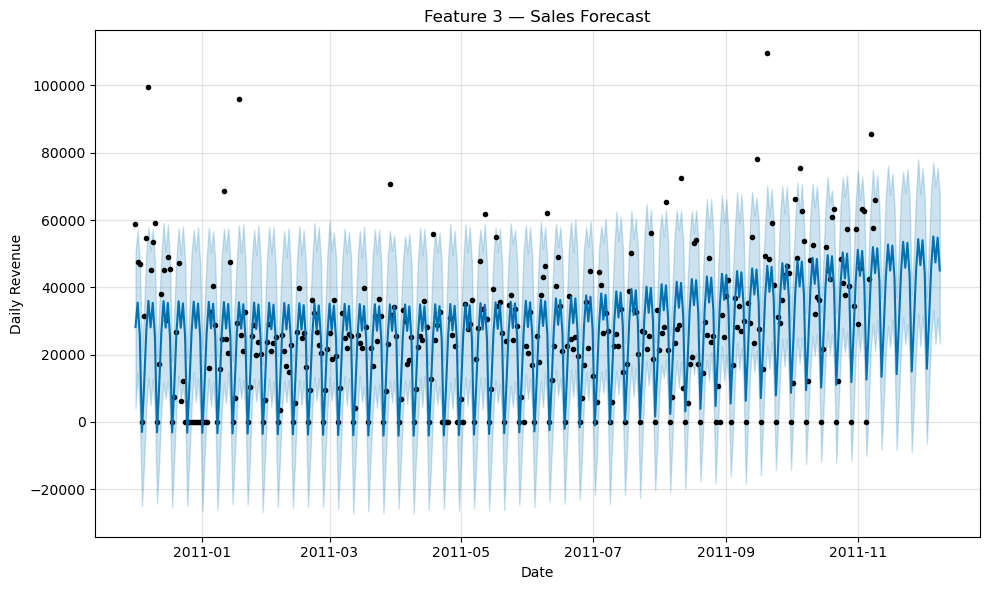

00:06:44 - cmdstanpy - INFO - Chain [1] start processing
00:06:44 - cmdstanpy - INFO - Chain [1] done processing



=== Feature 3: Tuning changepoint_prior_scale ===


00:06:45 - cmdstanpy - INFO - Chain [1] start processing
00:06:45 - cmdstanpy - INFO - Chain [1] done processing


  cps=0.01  MAE=24,395.39


00:06:45 - cmdstanpy - INFO - Chain [1] start processing
00:06:45 - cmdstanpy - INFO - Chain [1] done processing


  cps=0.05  MAE=20,260.29


00:06:45 - cmdstanpy - INFO - Chain [1] start processing
00:06:45 - cmdstanpy - INFO - Chain [1] done processing


  cps=0.1   MAE=18,485.55


00:06:45 - cmdstanpy - INFO - Chain [1] start processing
00:06:46 - cmdstanpy - INFO - Chain [1] done processing


  cps=0.5   MAE=17,300.59

Best cps=0.5 (MAE=17,300.59)
Prophet model saved: models/feature3_sales_forecast.pkl

=== Feature 3 alt: LightGBM with lags ===
LightGBM not installed — skipping.

=== FEATURE 3 COMPLETED SUCCESSFULLY ===


In [60]:

# ============================================================
# FEATURE 3: FUTURE SALES PREDICTION — Prophet (+ LightGBM alt)
# ============================================================

from prophet import Prophet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create folders if they don't exist
os.makedirs('reports', exist_ok=True)
os.makedirs('models', exist_ok=True)


# ------------------------------------------------------------
# 1. DAILY REVENUE (POSITIVE TRANSACTIONS ONLY)
# ------------------------------------------------------------

daily_rev = (
    df[df['Quantity'] > 0]
    .groupby(df[df['Quantity'] > 0]['InvoiceDate'].dt.date)['TotalAmount']
    .sum()
    .reset_index()
)

daily_rev.columns = ['ds', 'y']

daily_rev['ds'] = pd.to_datetime(daily_rev['ds'])

daily_rev = daily_rev.sort_values('ds').reset_index(drop=True)


# Fill missing calendar dates with zero revenue
full_dates = pd.date_range(
    start=daily_rev['ds'].min(),
    end=daily_rev['ds'].max(),
    freq='D'
)

daily_rev = (
    daily_rev.set_index('ds')
    .reindex(full_dates, fill_value=0)
    .rename_axis('ds')
    .reset_index()
)

daily_rev['y'] = daily_rev['y'].astype(float)


# ------------------------------------------------------------
# 2. CHRONOLOGICAL TRAIN-TEST SPLIT
# ------------------------------------------------------------

train_rev = daily_rev.iloc[:-30].copy()
test_rev = daily_rev.iloc[-30:].copy()

print(
    f"Prophet train: {len(train_rev)} days | "
    f"test: {len(test_rev)} days"
)


# ------------------------------------------------------------
# 3. PROPHET MODEL
# ------------------------------------------------------------

print("\n=== Feature 3: Prophet ===")

m3 = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.05,
    interval_width=0.90
)

m3.fit(train_rev)


# Generate dates covering training and test periods
future = pd.DataFrame({
    'ds': pd.date_range(
        start=train_rev['ds'].min(),
        end=test_rev['ds'].max(),
        freq='D'
    )
})

fcst = m3.predict(future)


# ------------------------------------------------------------
# 4. EVALUATION ON LAST 30 DAYS
# ------------------------------------------------------------

pred_test = (
    fcst.set_index('ds')
    .reindex(test_rev['ds'])['yhat']
    .values
)

mae3 = mean_absolute_error(
    test_rev['y'],
    pred_test
)

rmse3 = np.sqrt(
    mean_squared_error(test_rev['y'], pred_test)
)

mape3 = np.mean(
    np.abs(
        (test_rev['y'].values - pred_test) /
        test_rev['y'].clip(lower=1).values
    )
) * 100

print(
    f"MAE: {mae3:,.2f} | "
    f"RMSE: {rmse3:,.2f} | "
    f"MAPE: {mape3:.2f}%"
)


# ------------------------------------------------------------
# 5. PLOT SALES FORECAST
# ------------------------------------------------------------

fig = m3.plot(fcst)

plt.title('Feature 3 — Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Daily Revenue')

plt.tight_layout()

plt.savefig(
    'reports/feature3_sales_forecast.png',
    dpi=120
)

plt.show()


# ------------------------------------------------------------
# 6. TUNING CHANGEPOINT PRIOR SCALE
# ------------------------------------------------------------

print("\n=== Feature 3: Tuning changepoint_prior_scale ===")

best_cps = None
best_mae = np.inf

for cps in [0.01, 0.05, 0.1, 0.5]:

    m = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=cps
    )

    m.fit(train_rev)

    # Predict using the same complete date range
    f = m.predict(future)

    p = (
        f.set_index('ds')
        .reindex(test_rev['ds'])['yhat']
        .values
    )

    mae = mean_absolute_error(
        test_rev['y'],
        p
    )

    print(f"  cps={cps:<5} MAE={mae:,.2f}")

    if mae < best_mae:
        best_mae = mae
        best_cps = cps

print(
    f"\nBest cps={best_cps} "
    f"(MAE={best_mae:,.2f})"
)


# ------------------------------------------------------------
# 7. FINAL MODEL — REFIT ON ALL DATA
# ------------------------------------------------------------

final_m3 = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=best_cps,
    interval_width=0.90
)

final_m3.fit(daily_rev)


# Save final Prophet model
joblib.dump(
    final_m3,
    'models/feature3_sales_forecast.pkl'
)

print(
    "Prophet model saved: "
    "models/feature3_sales_forecast.pkl"
)


# ------------------------------------------------------------
# 8. ALTERNATIVE: LIGHTGBM WITH LAG FEATURES
# ------------------------------------------------------------

print("\n=== Feature 3 alt: LightGBM with lags ===")

try:

    import lightgbm as lgb

    rev_lgb = daily_rev.copy()

    # Lag features
    rev_lgb['lag1'] = rev_lgb['y'].shift(1)
    rev_lgb['lag7'] = rev_lgb['y'].shift(7)
    rev_lgb['lag14'] = rev_lgb['y'].shift(14)

    # Rolling average
    rev_lgb['rolling7'] = (
        rev_lgb['y']
        .shift(1)
        .rolling(7)
        .mean()
    )

    # Day of week
    rev_lgb['dow'] = rev_lgb['ds'].dt.dayofweek

    # Remove missing values
    rev_lgb = rev_lgb.dropna().reset_index(drop=True)


    # Features and target
    Xl = rev_lgb[
        ['lag1', 'lag7', 'lag14', 'rolling7', 'dow']
    ]

    yl = rev_lgb['y']


    # Chronological split
    split = len(rev_lgb) - 30

    Xl_tr = Xl.iloc[:split]
    Xl_te = Xl.iloc[split:]

    yl_tr = yl.iloc[:split]
    yl_te = yl.iloc[split:]


    # Train LightGBM
    lgbm = lgb.LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        random_state=42
    )

    lgbm.fit(Xl_tr, yl_tr)


    # Predictions
    pl = lgbm.predict(Xl_te)


    # Evaluation
    lgb_mae = mean_absolute_error(
        yl_te,
        pl
    )

    lgb_rmse = np.sqrt(
        mean_squared_error(yl_te, pl)
    )

    print(f"LightGBM MAE: {lgb_mae:,.2f}")
    print(f"LightGBM RMSE: {lgb_rmse:,.2f}")


    # Save LightGBM model
    joblib.dump(
        lgbm,
        'models/feature3_sales_lgbm.pkl'
    )

    print(
        "LightGBM model saved: "
        "models/feature3_sales_lgbm.pkl"
    )

except ImportError:

    print(
        "LightGBM not installed — skipping."
    )


print("\n=== FEATURE 3 COMPLETED SUCCESSFULLY ===")


In [61]:
# ============================================================
# FEATURE 4: CANCELLATION ACTIVITY FORECASTING — Prophet (counts)
# ============================================================
cancel_daily = (df[df['IsCancelled']]
                .groupby(df['InvoiceDate'].dt.date).size()
                .reset_index())
cancel_daily.columns = ['ds', 'y']
cancel_daily['ds'] = pd.to_datetime(cancel_daily['ds'])
cancel_daily = cancel_daily.sort_values('ds')

# Fill zero-cancellation days
full_range = pd.date_range(cancel_daily['ds'].min(), cancel_daily['ds'].max(), freq='D')
cancel_daily = (cancel_daily.set_index('ds')
                .reindex(full_range, fill_value=0)
                .rename_axis('ds').reset_index())

# Log-transform (counts are skewed) — use log1p then expm1
cancel_daily['y_log'] = np.log1p(cancel_daily['y'])

train_c = cancel_daily.iloc[:-30]
test_c  = cancel_daily.iloc[-30:]

print("\n=== Feature 4: Prophet on log1p(counts) ===")
m4 = Prophet(weekly_seasonality=True, yearly_seasonality=False,
             daily_seasonality=False, changepoint_prior_scale=0.1)
m4.fit(train_c[['ds','y_log']].rename(columns={'y_log':'y'}))
f4 = m4.predict(m4.make_future_dataframe(periods=30))

pred_log = f4.set_index('ds').loc[test_c['ds']]['yhat'].values
pred_cnt = np.expm1(pred_log)
pred_cnt = np.clip(pred_cnt, 0, None)

mae4  = mean_absolute_error(test_c['y'], pred_cnt)
rmse4 = np.sqrt(mean_squared_error(test_c['y'], pred_cnt))
print(f"MAE: {mae4:.2f} | RMSE: {rmse4:.2f}")
print(f"Actual mean cancellations/day: {test_c['y'].mean():.2f}")
print(f"Predicted mean cancellations/day: {pred_cnt.mean():.2f}")

# Refit on all data
final_m4 = Prophet(weekly_seasonality=True, yearly_seasonality=False,
                   daily_seasonality=False, changepoint_prior_scale=0.1,
                   interval_width=0.90)
final_m4.fit(cancel_daily[['ds','y_log']].rename(columns={'y_log':'y'}))
joblib.dump(final_m4, 'models/feature4_cancellation_forecast.pkl')
print("✅ Saved models/feature4_cancellation_forecast.pkl")

00:07:38 - cmdstanpy - INFO - Chain [1] start processing
00:07:38 - cmdstanpy - INFO - Chain [1] done processing



=== Feature 4: Prophet on log1p(counts) ===


00:07:38 - cmdstanpy - INFO - Chain [1] start processing
00:07:38 - cmdstanpy - INFO - Chain [1] done processing


MAE: 15.90 | RMSE: 23.96
Actual mean cancellations/day: 35.50
Predicted mean cancellations/day: 24.54
✅ Saved models/feature4_cancellation_forecast.pkl


In [64]:

# ============================================================
# FEATURE 6: UNUSUAL TRANSACTION DETECTION — Isolation Forest
# ============================================================

import numpy as np
import pandas as pd
import os
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest


# ------------------------------------------------------------
# 1. CREATE REQUIRED DIRECTORIES
# ------------------------------------------------------------

os.makedirs('models', exist_ok=True)
os.makedirs('reports', exist_ok=True)


# ------------------------------------------------------------
# 2. SELECT FEATURES
# ------------------------------------------------------------

feat6_cols = [
    'Quantity',
    'UnitPrice',
    'TotalAmount',
    'Hour'
]

df6 = df[feat6_cols].copy()


# ------------------------------------------------------------
# 3. DATA CLEANING
# ------------------------------------------------------------

# Convert features to numeric
df6 = df6.apply(pd.to_numeric, errors='coerce')

# Remove invalid and missing values
df6 = df6.replace([np.inf, -np.inf], np.nan)

df6 = df6.dropna()

# Sanity filtering
df6 = df6[
    (df6['UnitPrice'] >= 0) &
    (df6['Quantity'].abs() < 10000)
].copy()

print("Original rows:", len(df))
print("Valid rows for anomaly detection:", len(df6))
print("Excluded rows:", len(df) - len(df6))


# ------------------------------------------------------------
# 4. FEATURE SCALING
# ------------------------------------------------------------

scaler6 = StandardScaler()

X6 = scaler6.fit_transform(df6[feat6_cols])


# ------------------------------------------------------------
# 5. TUNING: CONTAMINATION SWEEP
# ------------------------------------------------------------

print("\n=== Feature 6: Isolation Forest — contamination sweep ===")

for c in [0.01, 0.02, 0.05]:

    iso = IsolationForest(
        contamination=c,
        random_state=42,
        n_jobs=-1
    )

    flags = iso.fit_predict(X6)

    n_anom = (flags == -1).sum()

    print(
        f"  contamination={c}: "
        f"{n_anom:,} anomalies "
        f"({n_anom / len(flags) * 100:.2f}%)"
    )


# ------------------------------------------------------------
# 6. FINAL ISOLATION FOREST MODEL
# ------------------------------------------------------------

iso_final = IsolationForest(
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

# Train model and generate predictions
anomaly_flags = iso_final.fit_predict(X6)

# Calculate anomaly scores
anomaly_scores = iso_final.score_samples(X6)


# ------------------------------------------------------------
# 7. ASSIGN RESULTS USING ORIGINAL INDEX
# ------------------------------------------------------------

# Initialize columns for all rows
df['AnomalyFlag'] = np.nan
df['AnomalyScore'] = np.nan

# Assign predictions only to valid rows
df.loc[df6.index, 'AnomalyFlag'] = anomaly_flags

df.loc[df6.index, 'AnomalyScore'] = anomaly_scores

# Convert anomaly flags to nullable integer
df['AnomalyFlag'] = df['AnomalyFlag'].astype('Int64')


# ------------------------------------------------------------
# 8. ANOMALY BREAKDOWN
# ------------------------------------------------------------

print("\nAnomaly breakdown:")

print(
    df['AnomalyFlag']
    .value_counts(dropna=False)
)

n_anomalies = (anomaly_flags == -1).sum()

print(f"\nTotal anomalies detected: {n_anomalies:,}")

print(
    f"Anomaly percentage: "
    f"{n_anomalies / len(df6) * 100:.2f}%"
)


# ------------------------------------------------------------
# 9. DISPLAY SAMPLE ANOMALIES
# ------------------------------------------------------------

print("\nSample anomalies:")

print(
    df.loc[
        df['AnomalyFlag'] == -1,
        [
            'InvoiceNo',
            'StockCode',
            'Quantity',
            'UnitPrice',
            'TotalAmount',
            'Country',
            'AnomalyScore'
        ]
    ].head(10)
)


# ------------------------------------------------------------
# 10. SAVE TRAINED MODEL AND SCALER
# ------------------------------------------------------------

joblib.dump(
    {
        'model': iso_final,
        'scaler': scaler6,
        'features': feat6_cols
    },
    'models/feature6_anomaly.pkl'
)

print("\nSaved: models/feature6_anomaly.pkl")


# ------------------------------------------------------------
# 11. EXPORT ANOMALY REPORT
# ------------------------------------------------------------

df[
    [
        'InvoiceNo',
        'StockCode',
        'AnomalyFlag',
        'AnomalyScore'
    ]
].to_csv(
    'reports/feature6_anomalies.csv',
    index=False
)

print("Saved: reports/feature6_anomalies.csv")


# ------------------------------------------------------------
# 12. COMPLETION
# ------------------------------------------------------------

print("\n=== FEATURE 6 COMPLETED SUCCESSFULLY ===")


Original rows: 536641
Valid rows for anomaly detection: 536634
Excluded rows: 7

=== Feature 6: Isolation Forest — contamination sweep ===
  contamination=0.01: 5,360 anomalies (1.00%)
  contamination=0.02: 10,733 anomalies (2.00%)
  contamination=0.05: 26,819 anomalies (5.00%)

Anomaly breakdown:
AnomalyFlag
1       525901
-1       10733
<NA>         7
Name: count, dtype: Int64

Total anomalies detected: 10,733
Anomaly percentage: 2.00%

Sample anomalies:
    InvoiceNo StockCode  Quantity  UnitPrice  TotalAmount         Country  \
45     536370      POST         3      18.00        54.00          France   
46     536371     22086        80       2.55       204.00  United Kingdom   
65     536374     21258        32      10.95       350.40  United Kingdom   
96     536378     21212       120       0.42        50.40  United Kingdom   
141   C536379         D        -1      27.50       -27.50  United Kingdom   
176    536386    85099C       100       1.65       165.00  United Kingdom   


In [65]:
# ============================================================
# FEATURE 7: FINANCIAL IMPACT — pure arithmetic
# ============================================================
total_credit = abs(df[df['IsCancelled']]['TotalAmount'].sum())
total_cancel_rows = df['IsCancelled'].sum()

print("=== Feature 7: Financial Impact Calculator ===")
print(f"Total cancellation rows: {total_cancel_rows:,}")
print(f"Total negative adjustment value: £{total_credit:,.2f}")

for pct in [0.10, 0.20, 0.30]:
    saving = total_credit * pct
    print(f"  If cancellations drop by {pct*100:.0f}% → potential saving £{saving:,.2f}")

# No model saved — this is a formula for the FastAPI endpoint
print("✅ Feature 7 requires no model — implement as endpoint /financial-impact")

=== Feature 7: Financial Impact Calculator ===
Total cancellation rows: 9,251
Total negative adjustment value: £893,979.73
  If cancellations drop by 10% → potential saving £89,397.97
  If cancellations drop by 20% → potential saving £178,795.95
  If cancellations drop by 30% → potential saving £268,193.92
✅ Feature 7 requires no model — implement as endpoint /financial-impact


In [66]:
# ============================================================
# FEATURE 8: PRODUCT ISSUE EARLY WARNING — statistical rule
# Compares last complete month vs prior month per product
# ============================================================

df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly = df.groupby(['StockCode', 'YearMonth']).agg(
    TotalRows=('InvoiceNo', 'size'),
    CancelRows=('IsCancelled', 'sum')
).reset_index()
monthly['Rate'] = monthly['CancelRows'] / monthly['TotalRows'].clip(lower=1)

months = sorted(monthly['YearMonth'].unique())
if len(months) >= 2:
    prev_m, curr_m = months[-2], months[-1]
    prev_df = monthly[monthly['YearMonth'] == prev_m][['StockCode','Rate']].rename(
        columns={'Rate':'PrevRate'})
    curr_df = monthly[monthly['YearMonth'] == curr_m][['StockCode','Rate']].rename(
        columns={'Rate':'CurrRate'})
    warn = prev_df.merge(curr_df, on='StockCode', how='inner')
    warn['RateChange'] = warn['CurrRate'] - warn['PrevRate']
    warn['RateRatio']  = warn['CurrRate'] / warn['PrevRate'].replace(0, np.nan)

    # Flag: rate more than doubled OR current rate > 15%
    warn['Warning'] = ((warn['RateRatio'] > 2.0) | (warn['CurrRate'] > 0.15))

    flagged = warn[warn['Warning']].sort_values('CurrRate', ascending=False)
    print(f"=== Feature 8: Early Warning ({prev_m} → {curr_m}) ===")
    print(f"Products flagged: {len(flagged)}")
    print(flagged[['StockCode','PrevRate','CurrRate','RateChange','RateRatio']].head(15))

    flagged.to_csv('reports/feature8_early_warnings.csv', index=False)
    print("✅ Saved reports/feature8_early_warnings.csv")

print("\nUpgrade path (Phase 2): CUSUM control chart or ruptures (PELT) per product.")

=== Feature 8: Early Warning (2011-11 → 2011-12) ===
Products flagged: 134
      StockCode  PrevRate  CurrRate  RateChange  RateRatio
121       20802  0.000000       1.0    1.000000        NaN
334       21422  0.000000       1.0    1.000000        NaN
1948      51008  0.000000       1.0    1.000000        NaN
664       22128  0.000000       1.0    1.000000        NaN
1209      22826  0.000000       1.0    1.000000        NaN
1631      23348  0.033898       1.0    0.966102       29.5
1984     72807C  0.166667       1.0    0.833333        6.0
2240     85159B  0.166667       1.0    0.833333        6.0
2299     90058A  0.000000       1.0    1.000000        NaN
2412  AMAZONFEE  1.000000       1.0    0.000000        1.0
2415       CRUK  1.000000       1.0    0.000000        1.0
2416          D  1.000000       1.0    0.000000        1.0
1357      23032  0.055556       1.0    0.944444       18.0
1892      37449  0.055556       0.6    0.544444       10.8
2263     85199L  0.000000       0.5    0

In [67]:
# ============================================================
# VERIFY ALL SAVED MODELS LOAD CORRECTLY
# ============================================================
print("=== Saved Models ===")
for f in sorted(os.listdir('models')):
    path = os.path.join('models', f)
    size_kb = os.path.getsize(path) / 1024
    try:
        joblib.load(path)
        status = "✅ loads OK"
    except Exception as e:
        status = f"❌ {e}"
    print(f"  {f:<40} {size_kb:>8.1f} KB  {status}")

print("\n=== Saved Reports ===")
for f in sorted(os.listdir('reports')):
    print(f"  {f}")

=== Saved Models ===
  feature1_product_risk.pkl                  4357.3 KB  ✅ loads OK
  feature2_customer_return.pkl                  1.9 KB  ✅ loads OK
  feature3_sales_forecast.pkl                  40.9 KB  ✅ loads OK
  feature4_cancellation_forecast.pkl           40.9 KB  ✅ loads OK
  feature6_anomaly.pkl                        766.9 KB  ✅ loads OK

=== Saved Reports ===
  feature1_confusion_matrix.png
  feature1_importance.csv
  feature1_importance.png
  feature3_sales_forecast.png
  feature6_anomalies.csv
  feature8_early_warnings.csv


In [71]:
# main.py — Step 11
from fastapi import FastAPI
from pydantic import BaseModel
import joblib, pandas as pd, numpy as np

app = FastAPI(title="Sales Manager Dashboard API")

# Load all models at startup
m1 = joblib.load('models/feature1_product_risk.pkl')
m2 = joblib.load('models/feature2_customer_return.pkl')
m3 = joblib.load('models/feature3_sales_forecast.pkl')
m4 = joblib.load('models/feature4_cancellation_forecast.pkl')
m6 = joblib.load('models/feature6_anomaly.pkl')

@app.get("/predict/product-risk/{stockcode}")
def product_risk(stockcode: str):
    # Look up features from prod_train, predict
    ...

@app.get("/forecast/sales?days=28")
def sales_forecast(days: int = 28):
    future = m3.make_future_dataframe(periods=days)
    fc = m3.predict(future)
    return fc[['ds','yhat','yhat_lower','yhat_upper']].tail(days).to_dict('records')

@app.post("/financial-impact")
def financial_impact(reduction_pct: float):
    total_credit = 1_000_000  # load from data
    return {"potential_saving": total_credit * reduction_pct}

In [69]:
pip install fastapi

  Using cached fastapi-0.165.0-py3-none-any.whl.metadata (27 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached annotated_doc-0.0.7-py3-none-any.whl.metadata (6.4 kB)
  Using cached opentelemetry_api-1.45.2-py3-none-any.whl.metadata (1.4 kB)
Using cached fastapi-0.165.0-py3-none-any.whl (159 kB)
Using cached annotated_doc-0.0.7-py3-none-any.whl (5.3 kB)
Using cached opentelemetry_api-1.45.2-py3-none-any.whl (60 kB)
Using cached starlette-1.10.0-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------------------------------------- 0/4 [opentelemetry-api]
   ---------- ----------------------------- 1/4 [annotated-doc]
   -------------------- ------------------- 2/4 [starlette]
   -------------------- --

In [72]:
pip install fastapi "uvicorn[standard]" pandas numpy scikit-learn prophet joblib

  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
Using cached uvicorn-0.54.0-py3-none-any.whl (87 kB)

   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ---------------------------------------- 0/4 [websockets]
   ------------------------